## On AB tests.

A lot has been said about experiments. Nevertheless, it is always important to go back to ifrst principles to see where everything comes from. This is the most important thing nowadays. You can ask AI to make you a very nice notebook about some shiny model and not understand anything. Therefore, nothing beats the good old first principles approach. This notebook explores that.

It creates a p value function from zero, starting from its definition, it explores how it behaves when treatments change, when estimates are noisy, and sample sizes change.

Additionally, it explores the estimation of the sample size for an AB test and how this one changes when we change MDE, and variance.


# How can we design an experiment:

To design an AB test you need:

- A randomized control and treatment group.
- An MDE: A minimum detectable effect. If you expect a very small detectable effect, you will need lots of data.
- Power: if the change really works, this is the chance your test will detect it.
- Alpha: is the false positive rate you’re willing to accept. It’s the probability of rejecting H0 when H0 is actually true, which is the Type I error.




First, I am just gonna plot two normal distributions (control and treatment) and the difference between individual values, because I can, and so we don't forget where this all comes from.

Note: these are individual values, not means. The raw data doesn't need to be normal. What matters for the test is that the difference in means is approximately normal, thanks to the central limit theorem. We will see that below when we simulate the null.

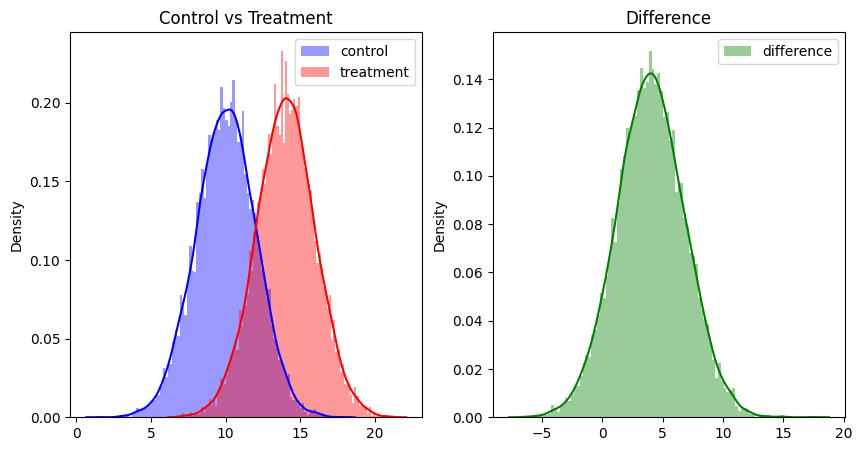

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
control=np.random.normal(10,2,10000)
treatment=np.random.normal(14,2,10000)


plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
sns.distplot(control,bins=100,color='blue',label='control')
sns.distplot(treatment,bins=100,color='red',label='treatment')
plt.title('Control vs Treatment')
plt.legend()
plt.subplot(1,2,2)
sns.distplot(treatment-control,bins=100,color='green',label='difference')
plt.title('Difference')
plt.legend()
plt.show()

Now, I am going to hard code the estimation of the p-value using the two distributions above.

The question is: if the treatment had no effect, how often would random noise alone
produce a difference at least as big as the one I observed?

Difference =  Mean Treatment - Mean control = 0 --> also known as the null hypothesis (H0)

Even if H0 is true, the sample averages will differ a bit just by chance.
The p-value is the probability of seeing a difference between means at least this large, assuming H0 is true.

If the p-value is small (below α, e.g. 0.05), the observed difference would be rare under H0,
so we reject H0.




In [22]:
#estimate p_value
#p-value is the probability of getting your observed results—or something even more extreme—purely by random chance, assuming the null hypothesis is true

miu=10
sigma=2
size=1000

def p_value(size,miu,miu_t,sigma):
  control=np.random.normal(miu,sigma,size)
  treatment=np.random.normal(miu_t,sigma,size)
  mean_diff=treatment.mean()-control.mean()

  null_diffs=[]
  for i in range(1000):
    control_a=np.random.normal(miu,sigma,size)
    control_b=np.random.normal(miu,sigma,size)
    null_diffs.append(control_b.mean()-control_a.mean())
  null_diffs=np.array(null_diffs)

  p_val=(np.abs(null_diffs)>=abs(mean_diff)).mean()
  return p_val

p_value(1000,10,10.2,2)


np.float64(0.08)

Lets see a distribution of p-values now, for the same function

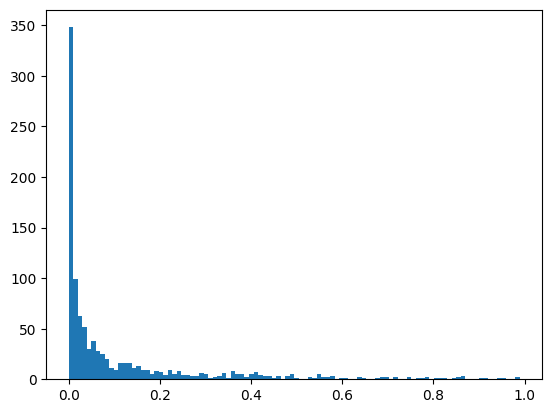

In [23]:
dist_p_values=[]
for i in range(1000):
  dist_p_values.append(p_value(1000,10,10.2,2))

plt.hist(dist_p_values,bins=100)
plt.show()

How will the p-value behave when we are dealing with big treatments, noisty variables, big volumes?

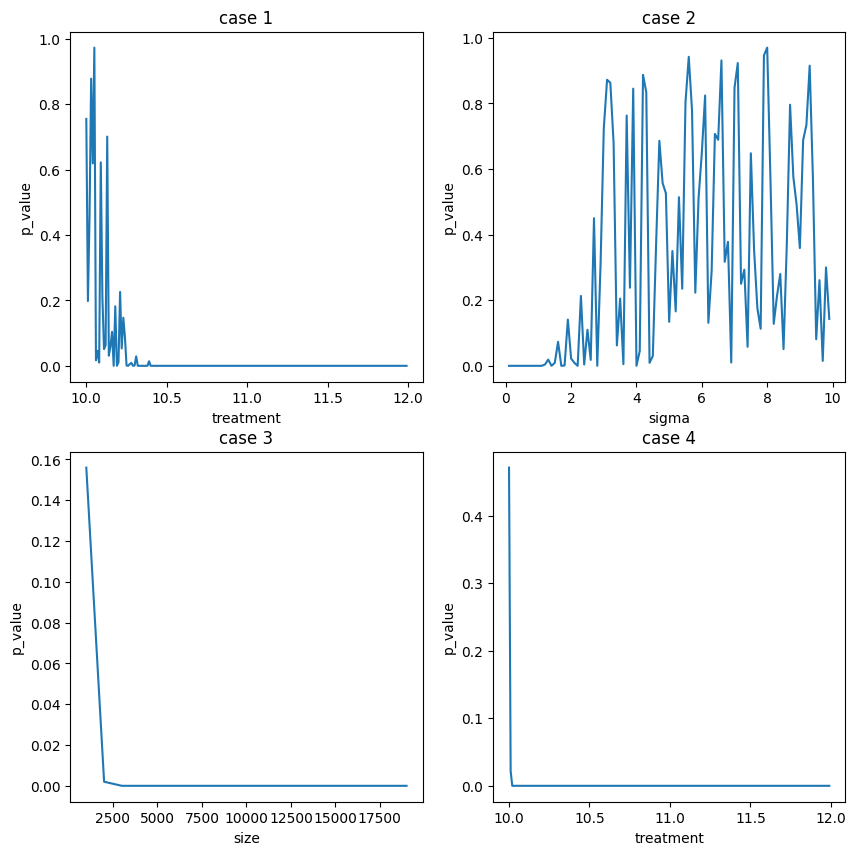

In [24]:
#plotting the behavior of different variables

#case 1: big_treatment--> 10:20
#case 2: noisy variables: sigma--> 0.1:10, stable difference
#case 3: big data volume: size: 1000:100000
#case 4: noisy but small treatment: t=12 ;se=0.1:10



plt.figure(figsize=(10,10))
plt.subplot(2,2,1)
treatments=np.arange(10,12,0.01)
plt.ylabel('p_value')
plt.xlabel('treatment')
plt.title('case 1')
plt.plot(treatments,[p_value(1000,10,t,2) for t in treatments])

plt.subplot(2,2,2)
plt.xlabel('sigma')
plt.ylabel('p_value')
plt.title('case 2')
plt.plot(np.arange(0.1,10,0.1),[p_value(1000,10,10.2,s) for s in np.arange(0.1,10,0.1)])

plt.subplot(2,2,3)
plt.xlabel('size')
plt.ylabel('p_value')
plt.title('case 3')
plt.plot(np.arange(1000,20000,1000),[p_value(s,10,10.2,2) for s in np.arange(1000,20000,1000)])

plt.subplot(2,2,4)
plt.xlabel('treatment')
plt.ylabel('p_value')
plt.title('case 4')
plt.plot(treatments,[p_value(1000,10,t,0.1) for t in treatments])



What are the combinations of miu and sigma that we will see that will behave under p_value < 0.05?

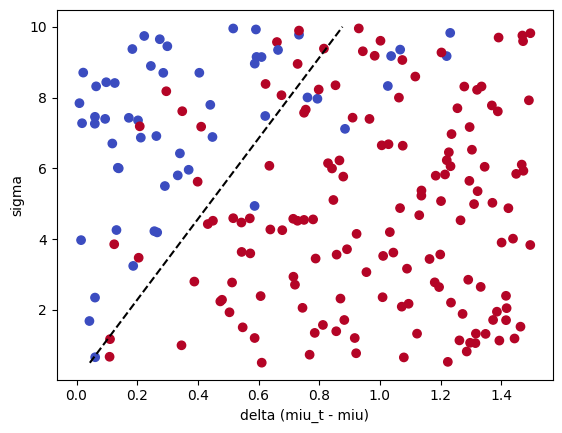

In [25]:
#now, lets keep p-value equals to 0.05 and variate the treatment u and se:



rng = np.random.default_rng(0)
alpha = 0.05
n = 1000

results = []
for i in range(200):
    miu_t = rng.uniform(10, 11.5)   # delta between 0 and 1.5
    sigma = rng.uniform(0.5, 10)    # no sigma = 0
    p = p_value(n, 10, miu_t, sigma)
    results.append((miu_t - 10, sigma, p <= alpha))

d, s, sig = np.array(results).T
plt.scatter(d, s, c=sig, cmap='coolwarm')

# theoretical boundary: delta = 1.96 * SE
s_line = np.linspace(0.5, 10, 50)
plt.plot(1.96 * s_line * np.sqrt(2 / n), s_line, 'k--')

plt.xlabel('delta (miu_t - miu)')
plt.ylabel('sigma')
plt.show()

## Choosing a sample size for our experiment

Now we move to estimation of the sample size:

For this we need to understand type I and type II errors:

Type I error: It is when you  believe there is an impact by the treatment, when in fact it does not exist.

Type II error: It is when you believe there is no real impact, when the treatment does exists

To choose a sample size, we want a balance between those two errors:

- alpha --> p-value --> Type I error
- beta --> power --> Type II error




## Type I error:

We control this error by choosing the critical value c so that, if H0 is true, the chance of a false positive is α. Since the test is two-sided, α is split between both tails:

$$P(\hat d > c \mid H_0) = \alpha/2$$

The probability that the observed difference is greater than c, given that H0 is true, equals α/2.

We usually pick α = 0.05. This puts c at 1.96 standard errors from 0:

$$c = z_{1-\alpha/2}\cdot SE = 1.96 \cdot SE$$

This holds for any sample size. The sample size matters for the Type II error (power).

## Type II error:

If the effect δ is real, we want to detect it with probability 1 − β (the power):

$$P(\hat d > c \mid H_1) = 1-\beta$$

We usually pick β = 0.2 (power = 0.8). This means c must sit 0.84 standard errors to the left of δ:

$$c = \delta - z_{1-\beta}\cdot SE = \delta - 0.84 \cdot SE$$

Since c is already fixed by the Type I error (c = 1.96·SE), both conditions can only hold if:

$$\delta = (1.96 + 0.84)\cdot SE$$

We control this error with the sample size: a larger n gives a smaller SE, until the equation holds.

$$\boxed{\,n = \frac{2\sigma^2\left(z_{1-\alpha/2} + z_{1-\beta}\right)^2}{\delta^2}\,}\quad\text{per group}$$


In [26]:
#To estimate this, we need to understand, how  what is the sample we need first:

power=0.8
p_value=0.05
n_a=10000
miu_a=100
sigma_a=3

MDE=1

n_b=10000
miu_b=miu_a+MDE
sigma_b=3

#this is taken from N(0,1) distribution
z_alpha=1.96
z_beta=0.84
sample= round(((2*sigma_a**2)*(z_alpha+z_beta)**2)/(MDE**2))


print(sample)




141


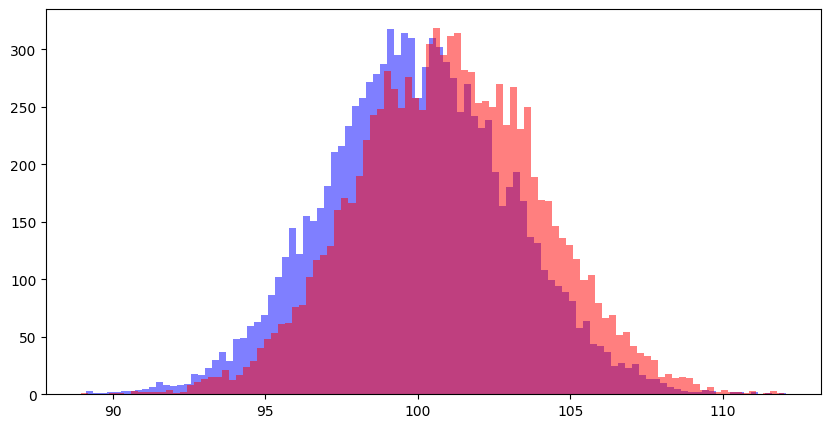

In [27]:

plt.figure(figsize=(10,5))
plt.hist(np.random.normal(miu_a,sigma_a,n_a),bins=100,alpha=0.5,color='blue')
plt.hist(np.random.normal(miu_b,sigma_b,n_b),bins=100,alpha=0.5,color='red')
plt.show()


Now, we see how sample size changes if we have a noisy data set and if we have a different Minimu detectable effect

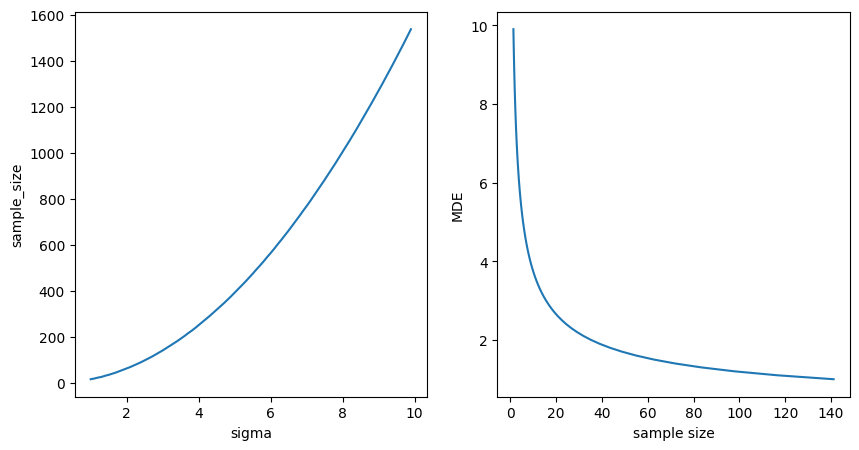

In [28]:
sigma_vector=[]
MDE_vector=[]

plt.figure(figsize=(10,5))

for i in np.arange(1,10,0.1):
  sigma_vector.append(round(((2*(i)**2)*(z_alpha+z_beta)**2)/(MDE**2)))
  MDE_vector.append(((2*sigma_a**2)*(z_alpha+z_beta)**2)/((i)**2))

plt.subplot(1,2,1)
plt.plot(np.arange(1,10,0.1),sigma_vector)
plt.xlabel('sigma')
plt.ylabel('sample_size')
plt.subplot(1,2,2)
plt.plot(MDE_vector,np.arange(1,10,0.1))
plt.ylabel('MDE')
plt.xlabel('sample size')
plt.show()
